# Previsão de cancelamento de clientes com Rede Neural (MLP)

## 1. Contexto do problema e dicionário de dados

**Origem:** dataset *Telco Customer Churn* (IBM), publicado no Kaggle em https://www.kaggle.com/datasets/blastchar/telco-customer-churn. Cada linha representa um cliente de uma operadora de telecomunicações.

**Objetivo de negócio:** prever se um cliente irá cancelar o serviço (*churn*). Reter um cliente custa menos do que conquistar um novo, então identificar antecipadamente quem tem alto risco de cancelamento permite que a empresa aja com ofertas e contato proativo.

**Tipo de problema:** classificação binária (`Cancelou` x `Permaneceu`).

| Coluna original | Coluna no projeto | Tipo | Significado prático |
|---|---|---|---|
| tenure | meses_contrato | numérica (int) | Meses de permanência do cliente na empresa |
| MonthlyCharges | cobranca_mensal | numérica (float) | Valor cobrado por mês, em dólares |
| TotalCharges | cobranca_total | numérica (float) | Valor total já cobrado do cliente, em dólares |
| Contract | tipo_contrato | categórica | Modalidade do contrato: mensal, 1 ano ou 2 anos |
| InternetService | servico_internet | categórica | Tipo de internet: DSL, fibra ótica ou nenhum |
| PaymentMethod | forma_pagamento | categórica | Forma de pagamento utilizada |
| PaperlessBilling | fatura_digital | categórica | Se o cliente aderiu à fatura digital (Yes/No) |
| TechSupport | suporte_tecnico | categórica | Se possui suporte técnico (Yes/No/No internet service) |
| OnlineSecurity | seguranca_online | categórica | Se possui segurança online (Yes/No/No internet service) |
| Churn | cancelou (alvo) | categórica | Se o cliente cancelou o serviço |

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    matthews_corrcoef,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEMENTE = 77

In [2]:
COLUNAS = {
    "tenure": "meses_contrato",
    "MonthlyCharges": "cobranca_mensal",
    "TotalCharges": "cobranca_total",
    "Contract": "tipo_contrato",
    "InternetService": "servico_internet",
    "PaymentMethod": "forma_pagamento",
    "PaperlessBilling": "fatura_digital",
    "TechSupport": "suporte_tecnico",
    "OnlineSecurity": "seguranca_online",
    "Churn": "cancelou",
}

bruto = pd.read_csv(Path("..") / "data" / "dataset.csv")
df = bruto[list(COLUNAS)].rename(columns=COLUNAS)
df["cobranca_total"] = pd.to_numeric(df["cobranca_total"], errors="coerce")
df.head()

,meses_contrato,cobranca_mensal,cobranca_total,tipo_contrato,servico_internet,forma_pagamento,fatura_digital,suporte_tecnico,seguranca_online,cancelou
0,1,29.85,29.85,Month-to-month,DSL,Electronic check,Yes,No,No,No
1,34,56.95,1889.50,One year,DSL,Mailed check,No,No,Yes,No
2,2,53.85,108.15,Month-to-month,DSL,Mailed check,Yes,No,Yes,Yes
3,45,42.30,1840.75,One year,DSL,Bank transfer (automatic),No,Yes,Yes,No
4,2,70.70,151.65,Month-to-month,Fiber optic,Electronic check,Yes,No,No,Yes


## 2. Análise exploratória resumida

In [3]:
print("Dimensões (linhas, colunas):", df.shape)
print()
print("Tipos de dados:")
print(df.dtypes)
print()
print("Valores ausentes por coluna:")
print(df.isnull().sum())

Dimensões (linhas, colunas): (7043, 10)

Tipos de dados:
meses_contrato        int64
cobranca_mensal     float64
cobranca_total      float64
tipo_contrato           str
servico_internet        str
forma_pagamento         str
fatura_digital          str
suporte_tecnico         str
seguranca_online        str
cancelou                str
dtype: object

Valores ausentes por coluna:
meses_contrato       0
cobranca_mensal      0
cobranca_total      11
tipo_contrato        0
servico_internet     0
forma_pagamento      0
fatura_digital       0
suporte_tecnico      0
seguranca_online     0
cancelou             0
dtype: int64


A coluna `cobranca_total` vem como texto no arquivo original e possui valores em branco, que viram nulos após a conversão numérica. Eles correspondem a clientes com `meses_contrato` igual a 0, que ainda não receberam nenhuma cobrança. Por isso o valor correto é 0, e não uma média.

In [4]:
sem_cobranca = df["cobranca_total"].isnull()
print("Registros com cobranca_total nula:", sem_cobranca.sum())
print("Meses de contrato desses registros:", df.loc[sem_cobranca, "meses_contrato"].unique())

df["cobranca_total"] = df["cobranca_total"].fillna(0.0)
print("Nulos restantes:", df.isnull().sum().sum())

Registros com cobranca_total nula: 11
Meses de contrato desses registros: [0]
Nulos restantes: 0


            quantidade  proporcao
cancelou                         
Permaneceu        5174      0.735
Cancelou          1869      0.265


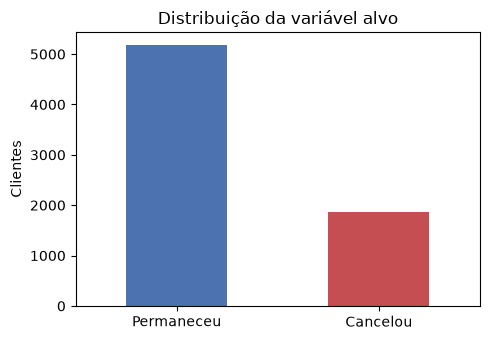

In [5]:
df["cancelou"] = df["cancelou"].map({"No": "Permaneceu", "Yes": "Cancelou"})

contagem = df["cancelou"].value_counts()
proporcao = df["cancelou"].value_counts(normalize=True).round(3)
print(pd.DataFrame({"quantidade": contagem, "proporcao": proporcao}))

fig, ax = plt.subplots(figsize=(5, 3.5))
contagem.plot(kind="bar", ax=ax, color=["#4c72b0", "#c44e52"])
ax.set_title("Distribuição da variável alvo")
ax.set_xlabel("")
ax.set_ylabel("Clientes")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

A base é desbalanceada, com minoria de cancelamentos. Por isso a acurácia sozinha engana, e o coeficiente de Matthews e as métricas por classe são fundamentais na avaliação.

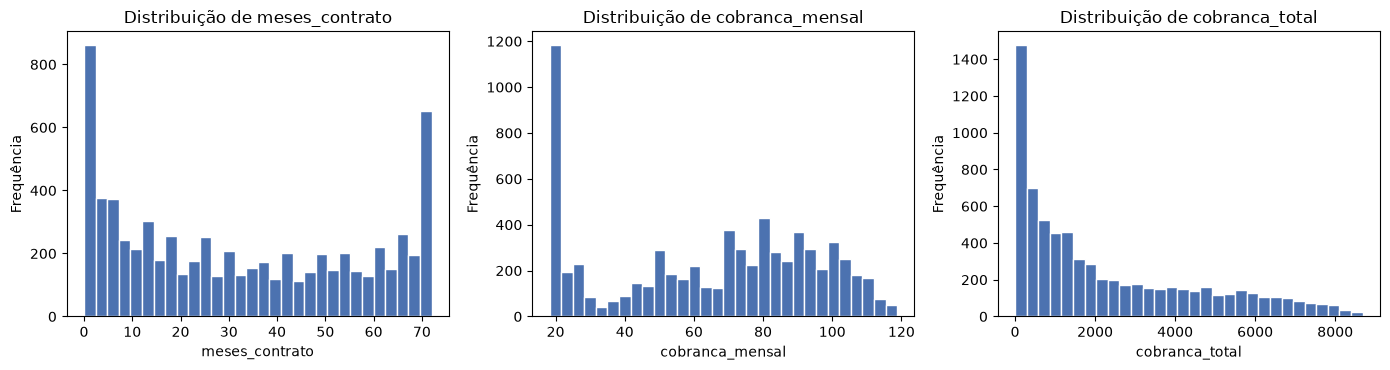

In [6]:
NUMERICAS = ["meses_contrato", "cobranca_mensal", "cobranca_total"]

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))
for eixo, coluna in zip(eixos, NUMERICAS):
    df[coluna].plot(kind="hist", bins=30, ax=eixo, color="#4c72b0", edgecolor="white")
    eixo.set_title(f"Distribuição de {coluna}")
    eixo.set_xlabel(coluna)
    eixo.set_ylabel("Frequência")
plt.tight_layout()
plt.show()

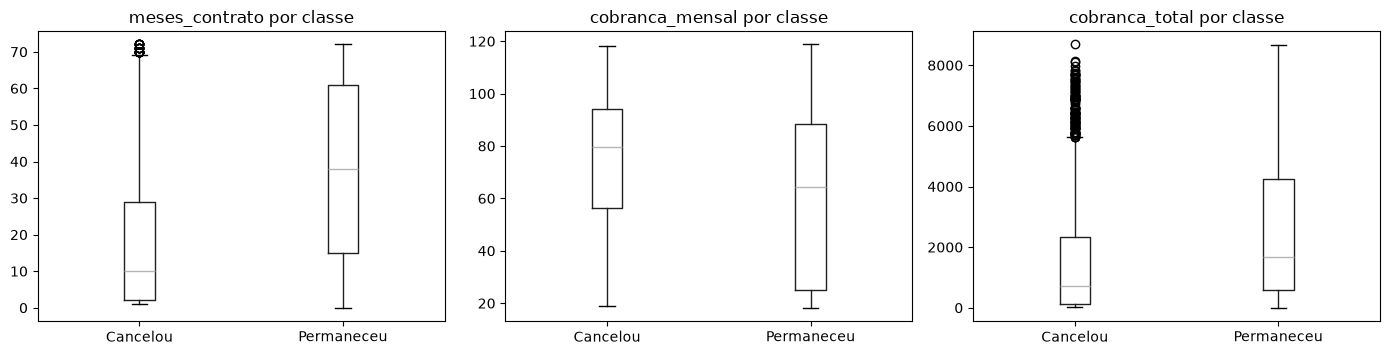

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))
for eixo, coluna in zip(eixos, NUMERICAS):
    df.boxplot(column=coluna, by="cancelou", ax=eixo, grid=False)
    eixo.set_title(f"{coluna} por classe")
    eixo.set_xlabel("")
fig.suptitle("")
plt.tight_layout()
plt.show()

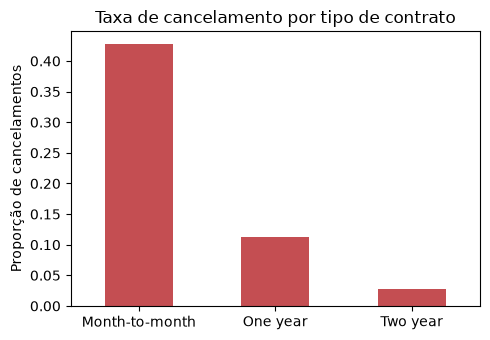

In [8]:
taxa = (
    df.assign(cancelou_num=(df["cancelou"] == "Cancelou").astype(int))
    .groupby("tipo_contrato")["cancelou_num"]
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(5, 3.5))
taxa.plot(kind="bar", ax=ax, color="#c44e52")
ax.set_title("Taxa de cancelamento por tipo de contrato")
ax.set_xlabel("")
ax.set_ylabel("Proporção de cancelamentos")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 3. Construção do pipeline Scikit-Learn

In [9]:
CATEGORICAS = [
    "tipo_contrato",
    "servico_internet",
    "forma_pagamento",
    "fatura_digital",
    "suporte_tecnico",
    "seguranca_online",
]

X = df[NUMERICAS + CATEGORICAS]
y = df["cancelou"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMENTE
)

print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
print("Proporção de cancelamentos no treino:", round((y_treino == "Cancelou").mean(), 3))
print("Proporção de cancelamentos no teste:", round((y_teste == "Cancelou").mean(), 3))

Treino: (5634, 9) | Teste: (1409, 9)
Proporção de cancelamentos no treino: 0.265
Proporção de cancelamentos no teste: 0.265


In [10]:
preprocessador = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), NUMERICAS),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
    ]
)

rede_neural = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=SEMENTE,
)

pipeline = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        ("rede_neural", rede_neural),
    ]
)

pipeline.fit(X_treino, y_treino)
print("Iterações executadas:", pipeline.named_steps["rede_neural"].n_iter_)
print("Classes:", list(pipeline.classes_))

Iterações executadas: 29
Classes: [np.str_('Cancelou'), np.str_('Permaneceu')]


## 4. Avaliação do modelo

In [11]:
y_previsto = pipeline.predict(X_teste)

acuracia = accuracy_score(y_teste, y_previsto)
mcc = matthews_corrcoef(y_teste, y_previsto)

print(f"Acurácia global: {acuracia:.4f}")
print(f"Coeficiente de Matthews (MCC): {mcc:.4f}")
print()
print(classification_report(y_teste, y_previsto, digits=4))

Acurácia global: 0.8020
Coeficiente de Matthews (MCC): 0.4529

              precision    recall  f1-score   support

    Cancelou     0.6753    0.4893    0.5674       374
  Permaneceu     0.8322    0.9150    0.8716      1035

    accuracy                         0.8020      1409
   macro avg     0.7537    0.7021    0.7195      1409
weighted avg     0.7905    0.8020    0.7909      1409



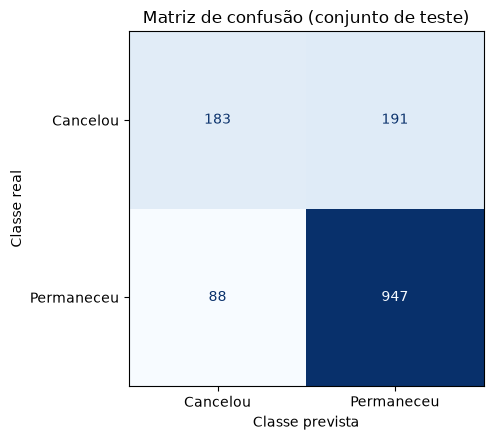

In [12]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, y_previsto, ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("Matriz de confusão (conjunto de teste)")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

**Interpretação.** Falsos negativos (cliente que cancelou, mas o modelo previu que permaneceria) são o erro mais custoso para o negócio, pois a empresa perde a chance de agir. Falsos positivos geram apenas uma ação de retenção desnecessária. O recall da classe `Cancelou` e o MCC indicam o quão bem o modelo lida com a classe minoritária.

## 5. Exportação do modelo treinado

O pipeline completo é serializado, de modo que a API receba dados brutos e aplique escalonamento e codificação automaticamente, sem risco de inconsistência de pré-processamento.

In [13]:
pasta_modelos = Path("..") / "models"
pasta_modelos.mkdir(exist_ok=True)
caminho_modelo = pasta_modelos / "pipeline_rede_neural.joblib"

joblib.dump(pipeline, caminho_modelo)
print("Modelo salvo em:", caminho_modelo.resolve())

Modelo salvo em: C:\Users\Usuário\Downloads\am-at2-redes-neurais\am-at2-redes-neurais\models\pipeline_rede_neural.joblib


In [14]:
pipeline_carregado = joblib.load(caminho_modelo)
amostra = X_teste.iloc[[0]]
probabilidades = pipeline_carregado.predict_proba(amostra)[0]
print(dict(zip(pipeline_carregado.classes_, probabilidades.round(4))))

{np.str_('Cancelou'): np.float64(0.6325), np.str_('Permaneceu'): np.float64(0.3675)}
